# EfficientNet-B0 fine-tuning on the cached ISIC data (binary: melanoma vs. not)

Uses `images_uint8.npy` + `metadata.csv` only (no JPEGs needed).

**Plan**
1. Copy the cache from Drive to Colab's local disk (fast random access)
2. Dataset reads straight from the memory-mapped array; augmentation and normalisation run on the GPU
3. **Phase 1:** freeze the backbone and train only the new classifier head
4. **Phase 2:** unfreeze the last blocks and fine-tune with a lower learning rate
5. Pick the best epoch by validation ROC-AUC, choose a decision threshold on **val**, then report final metrics on **test**

Set the runtime to **GPU** (Runtime > Change runtime type > T4 GPU).

## 1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/jpeg_256'
CKPT_DIR  = '/content/drive/MyDrive/jpeg_256/isic_checkpoints'

import os, shutil, json
os.makedirs(CKPT_DIR, exist_ok=True)
LOCAL_DIR = '/content/cache'
os.makedirs(LOCAL_DIR, exist_ok=True)
for f in ['images_uint8.npy', 'metadata.csv', 'manifest.json']:
    dst = f'{LOCAL_DIR}/{f}'
    if not os.path.exists(dst):
        print('copying', f, '...')
        shutil.copy(f'{DRIVE_DIR}/{f}', dst)

manifest = json.load(open(f'{LOCAL_DIR}/manifest.json'))
print('manifest complete:', manifest.get('complete'), '| shape:', manifest.get('shape'))
assert manifest.get('complete'), 'Cache is not complete - some images may be all zeros. Re-run the caching step.'

Mounted at /content/drive
copying images_uint8.npy ...
copying metadata.csv ...
copying manifest.json ...
manifest complete: True | shape: [32701, 256, 256, 3]


In [2]:
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, time, random
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, f1_score, balanced_accuracy_score)
import matplotlib.pyplot as plt

# ----- Config -----
SEED         = 42
IMG_SIZE     = 224        # model input size (cache is downscaled to this on the GPU if larger)
BATCH_SIZE   = 64
PHASE1_EPOCHS, PHASE1_LR = 5, 1e-3     # head only
PHASE2_EPOCHS, PHASE2_LR = 10, 1e-4     # last blocks + head
UNFREEZE_FROM = 6       # EfficientNet-B0 has features[0..8]; unfreeze features[6:] in phase 2
WEIGHT_DECAY = 1e-4
NUM_WORKERS  = 2
SPLIT_COL    = 'split_patient'   # use patient-level splits (NOT split_random)
LABEL_COL    = 'target'

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '(no GPU - training will be very slow)')

IMG_PATH = f'{LOCAL_DIR}/images_uint8.npy'
meta = pd.read_csv(f'{LOCAL_DIR}/metadata.csv')
imgs_probe = np.load(IMG_PATH, mmap_mode='r')
print('cache array:', imgs_probe.shape, imgs_probe.dtype)
assert len(meta) == len(imgs_probe)

train_df = meta[meta[SPLIT_COL] == 'train'].reset_index(drop=True)
val_df   = meta[meta[SPLIT_COL] == 'val'].reset_index(drop=True)
test_df  = meta[meta[SPLIT_COL] == 'test'].reset_index(drop=True)
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'{name:5s}: {len(d):6,d} images | {d[LABEL_COL].sum():5,d} positives ({d[LABEL_COL].mean():.2%}) | {d.patient_id.nunique():5,d} patients')

device: cuda Tesla T4
cache array: (32701, 256, 256, 3) uint8
train: 23,364 images |   414 positives (1.77%) | 1,469 patients
val  :  4,663 images |    85 positives (1.82%) |   292 patients
test :  4,674 images |    82 positives (1.75%) |   295 patients


## 2. Data: dataset reads the memory-mapped cache, augmentation runs on the GPU

/tmp/ipykernel_1248/2913714250.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(np.ascontiguousarray(self.imgs[self.idx[i]]))   # H,W,3 uint8
/tmp/ipykernel_1248/2913714250.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213

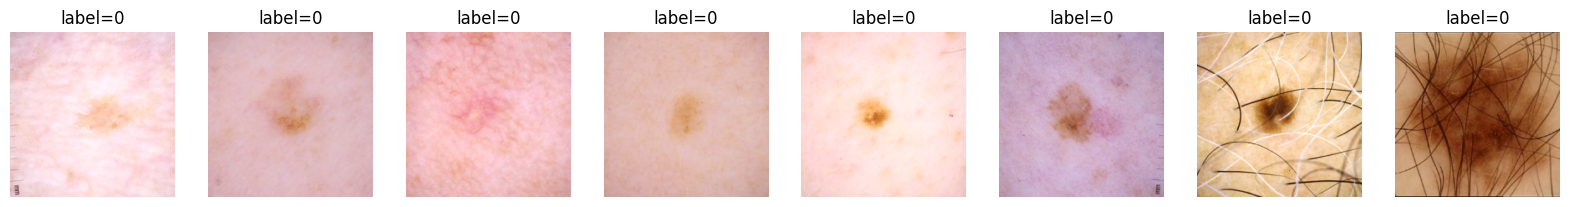

In [3]:
class CacheDataset(Dataset):
    def __init__(self, df):
        self.idx = df['cache_index'].values
        self.y = df[LABEL_COL].values.astype(np.float32)
        self.imgs = None                       # opened lazily so each worker gets its own handle
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        if self.imgs is None:
            self.imgs = np.load(IMG_PATH, mmap_mode='r')
        x = torch.from_numpy(np.ascontiguousarray(self.imgs[self.idx[i]]))   # H,W,3 uint8
        return x, torch.tensor(self.y[i])

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def gpu_prepare(x, train):
    """x: uint8 (B,H,W,3) on GPU -> normalised float (B,3,IMG_SIZE,IMG_SIZE), with light augmentation if train."""
    x = x.permute(0, 3, 1, 2).float() / 255.0
    if train:
        B = x.size(0)
        # random horizontal / vertical flips (per sample)
        m = torch.rand(B, device=x.device) < 0.5; x = torch.where(m.view(-1, 1, 1, 1), x.flip(3), x)
        m = torch.rand(B, device=x.device) < 0.5; x = torch.where(m.view(-1, 1, 1, 1), x.flip(2), x)
        # random 90-degree rotation (per batch - lesions have no canonical orientation)
        x = torch.rot90(x, k=random.randint(0, 3), dims=(2, 3))
        # brightness / contrast jitter (per sample)
        b = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.3
        c = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.3
        mu = x.mean(dim=(1, 2, 3), keepdim=True)
        x = ((x - mu) * c + mu) * b
        x = x.clamp(0, 1)
    if x.shape[-1] != IMG_SIZE:
        x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', antialias=True, align_corners=False)
    return (x - MEAN) / STD

def make_loader(df, shuffle):
    return DataLoader(CacheDataset(df), batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)

train_loader = make_loader(train_df, True)
val_loader   = make_loader(val_df, False)
test_loader  = make_loader(test_df, False)

# quick visual sanity check
xb, yb = next(iter(train_loader))
xb_vis = gpu_prepare(xb[:8].to(device), train=True) * STD + MEAN
fig, axs = plt.subplots(1, 8, figsize=(20, 3))
for a, im, y in zip(axs, xb_vis.clamp(0, 1).cpu(), yb[:8]):
    a.imshow(im.permute(1, 2, 0)); a.set_title(f'label={int(y)}'); a.axis('off')
plt.show()

## 3. Model: EfficientNet-B0 with a new classification head

In [4]:
weights = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = torchvision.models.efficientnet_b0(weights=weights)
in_feats = model.classifier[1].in_features            # 1280
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_feats, 1))   # 1 logit = binary
model = model.to(device)

def set_trainable(model, unfreeze_from=None):
    """unfreeze_from=None -> head only. Otherwise also unfreeze model.features[unfreeze_from:]."""
    for p in model.parameters(): p.requires_grad = False
    for p in model.classifier.parameters(): p.requires_grad = True
    if unfreeze_from is not None:
        for blk in model.features[unfreeze_from:]:
            for p in blk.parameters(): p.requires_grad = True
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'trainable params: {tr:,} / {sum(p.numel() for p in model.parameters()):,}')

def set_train_mode(model, unfreeze_from=None):
    """Frozen BatchNorm layers stay in eval mode so their ImageNet statistics are not overwritten."""
    model.eval()
    model.classifier.train()
    if unfreeze_from is not None:
        for blk in model.features[unfreeze_from:]: blk.train()

# Class imbalance: weight positives in the loss (sqrt of the neg/pos ratio is a gentler, more stable choice)
n_pos, n_neg = train_df[LABEL_COL].sum(), (1 - train_df[LABEL_COL]).sum()
pos_weight = torch.tensor([float(np.sqrt(n_neg / n_pos))], device=device)
print('pos_weight:', pos_weight.item())
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


pos_weight: 7.445453643798828


## 4. Training and evaluation helpers

In [5]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys, loss_sum, n = [], [], 0.0, 0
    for x, y in loader:
        x = gpu_prepare(x.to(device, non_blocking=True), train=False); y = y.to(device)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=device == 'cuda'):
            logits = model(x).squeeze(1)
        loss_sum += criterion(logits.float(), y).item() * len(y); n += len(y)
        probs.append(torch.sigmoid(logits.float()).cpu().numpy()); ys.append(y.cpu().numpy())
    return np.concatenate(ys), np.concatenate(probs), loss_sum / n

history = []
best = {'auc': -1, 'epoch': None}
scaler = torch.amp.GradScaler('cuda', enabled=device == 'cuda')

def run_phase(name, epochs, lr, unfreeze_from):
    global best
    set_trainable(model, unfreeze_from)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_loader), pct_start=0.2)
    for ep in range(1, epochs + 1):
        set_train_mode(model, unfreeze_from)
        t0, run_loss, n = time.time(), 0.0, 0
        for x, y in train_loader:
            x = gpu_prepare(x.to(device, non_blocking=True), train=True); y = y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=device == 'cuda'):
                logits = model(x).squeeze(1)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(y); n += len(y)
        yv, pv, vloss = predict(model, val_loader)
        auc, ap = roc_auc_score(yv, pv), average_precision_score(yv, pv)
        history.append(dict(phase=name, train_loss=run_loss / n, val_loss=vloss, val_auc=auc, val_ap=ap))
        flag = ''
        if auc > best['auc']:
            best = {'auc': auc, 'epoch': len(history)}
            torch.save(model.state_dict(), f'{CKPT_DIR}/effnet_b0_best.pt'); flag = '  <- best, saved'
        print(f'[{name}] epoch {ep}/{epochs} | train loss {run_loss/n:.4f} | val loss {vloss:.4f} | '
              f'val AUC {auc:.4f} | val AP {ap:.4f} | {time.time()-t0:.0f}s{flag}')

## 5. Train
Phase 1 trains only the new head; phase 2 also fine-tunes the last EfficientNet blocks.

In [6]:
run_phase('phase1-head', PHASE1_EPOCHS, PHASE1_LR, unfreeze_from=None)

trainable params: 1,281 / 4,008,829


/tmp/ipykernel_1248/2013935770.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
/tmp/ipykernel_1248/2913714250.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(np.ascont

[phase1-head] epoch 1/5 | train loss 0.4347 | val loss 0.3525 | val AUC 0.8109 | val AP 0.0717 | 54s  <- best, saved
[phase1-head] epoch 2/5 | train loss 0.3189 | val loss 0.3277 | val AUC 0.8275 | val AP 0.0914 | 24s  <- best, saved
[phase1-head] epoch 3/5 | train loss 0.3006 | val loss 0.3278 | val AUC 0.8316 | val AP 0.0956 | 23s  <- best, saved
[phase1-head] epoch 4/5 | train loss 0.2939 | val loss 0.3226 | val AUC 0.8349 | val AP 0.1011 | 23s  <- best, saved
[phase1-head] epoch 5/5 | train loss 0.2911 | val loss 0.3208 | val AUC 0.8343 | val AP 0.1011 | 23s


In [7]:
run_phase('phase2-finetune', PHASE2_EPOCHS, PHASE2_LR, unfreeze_from=UNFREEZE_FROM)
print('\nBest val AUC:', round(best['auc'], 4), 'at epoch', best['epoch'])

trainable params: 3,157,021 / 4,008,829
[phase2-finetune] epoch 1/10 | train loss 0.6181 | val loss 0.3216 | val AUC 0.8379 | val AP 0.1105 | 31s  <- best, saved
[phase2-finetune] epoch 2/10 | train loss 0.2943 | val loss 0.2893 | val AUC 0.8713 | val AP 0.1708 | 30s  <- best, saved
[phase2-finetune] epoch 3/10 | train loss 0.2421 | val loss 0.2916 | val AUC 0.8766 | val AP 0.1435 | 31s  <- best, saved
[phase2-finetune] epoch 4/10 | train loss 0.1959 | val loss 0.3178 | val AUC 0.8639 | val AP 0.1301 | 29s
[phase2-finetune] epoch 5/10 | train loss 0.1625 | val loss 0.3302 | val AUC 0.8727 | val AP 0.1480 | 30s
[phase2-finetune] epoch 6/10 | train loss 0.1300 | val loss 0.3259 | val AUC 0.8804 | val AP 0.1590 | 30s  <- best, saved
[phase2-finetune] epoch 7/10 | train loss 0.1048 | val loss 0.3421 | val AUC 0.8758 | val AP 0.1563 | 29s
[phase2-finetune] epoch 8/10 | train loss 0.0891 | val loss 0.3618 | val AUC 0.8786 | val AP 0.1559 | 30s
[phase2-finetune] epoch 9/10 | train loss 0.0701

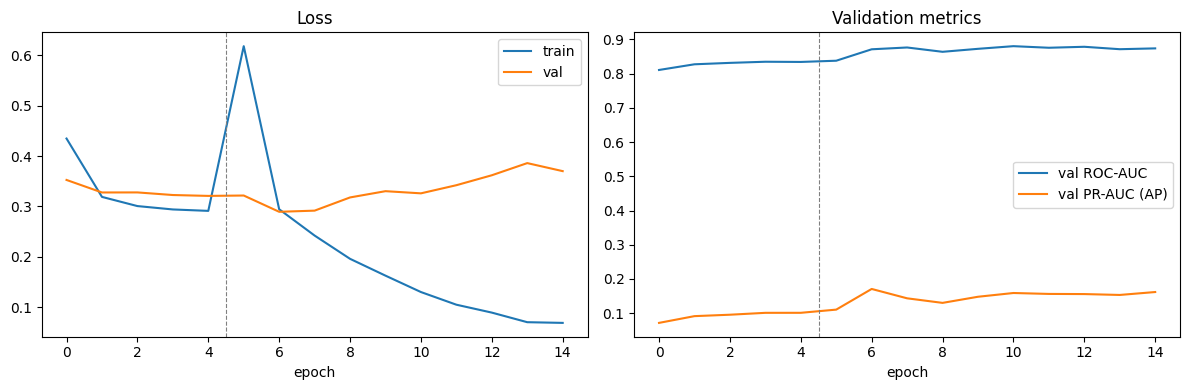

In [8]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.train_loss, label='train'); ax[0].plot(h.val_loss, label='val'); ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h.val_auc, label='val ROC-AUC'); ax[1].plot(h.val_ap, label='val PR-AUC (AP)'); ax[1].set_title('Validation metrics'); ax[1].set_xlabel('epoch'); ax[1].legend()
for a in ax: a.axvline(PHASE1_EPOCHS - 0.5, color='gray', ls='--', lw=0.8)   # phase boundary
plt.tight_layout(); plt.show()

In [9]:
def count_params(model, label=''):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = total - trainable
    pct = 100 * trainable / total if total else 0
    print(f'{label} Total: {total:,} | Trainable: {trainable:,} ({pct:.1f}%) | Frozen: {frozen:,}')
    return total, trainable, frozen

count_params(model, '[EfficientNet-B0]')

[EfficientNet-B0] Total: 4,008,829 | Trainable: 3,157,021 (78.8%) | Frozen: 851,808


(4008829, 3157021, 851808)

## 6. Evaluation on the held-out sets

- Reload the best checkpoint (by val ROC-AUC).
- ROC-AUC and PR-AUC are threshold-free; the confusion matrix, sensitivity, specificity, precision and F1 need a threshold.
- The threshold is chosen on the **validation** set (never on test) and then applied unchanged to test.

In [10]:
model.load_state_dict(torch.load(f'{CKPT_DIR}/effnet_b0_best.pt', map_location=device))
yv, pv, _ = predict(model, val_loader)
yt, pt, tloss = predict(model, test_loader)

# Threshold chosen on validation: maximise Youden's J (sensitivity + specificity - 1)
fpr_v, tpr_v, thr_v = roc_curve(yv, pv)
thr_youden = thr_v[np.argmax(tpr_v - fpr_v)]
# Alternative: maximise F1 on validation
p_, r_, t_ = precision_recall_curve(yv, pv)
f1s = 2 * p_[:-1] * r_[:-1] / (p_[:-1] + r_[:-1] + 1e-12)
thr_f1 = t_[np.argmax(f1s)]
print(f'Threshold (Youden J on val): {thr_youden:.4f} | Threshold (max F1 on val): {thr_f1:.4f}')

def report(y, p, thr, title):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    sens, spec = tp / (tp + fn + 1e-12), tn / (tn + fp + 1e-12)
    prec = tp / (tp + fp + 1e-12)
    print(f'--- {title} (threshold {thr:.4f}) ---')
    print(f'ROC-AUC           : {roc_auc_score(y, p):.4f}')
    print(f'PR-AUC (AP)       : {average_precision_score(y, p):.4f}   (random baseline = {y.mean():.4f})')
    print(f'Sensitivity/Recall: {sens:.4f}')
    print(f'Specificity       : {spec:.4f}')
    print(f'Precision (PPV)   : {prec:.4f}')
    print(f'F1                : {f1_score(y, pred):.4f}')
    print(f'Balanced accuracy : {balanced_accuracy_score(y, pred):.4f}')
    print(f'Confusion matrix  : TN={tn} FP={fp} FN={fn} TP={tp}\n')
    print(classification_report(y, pred, target_names=['benign', 'melanoma'], digits=3))

report(yv, pv, thr_youden, 'VALIDATION')
report(yt, pt, thr_youden, 'TEST')

/tmp/ipykernel_1248/2913714250.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(np.ascontiguousarray(self.imgs[self.idx[i]]))   # H,W,3 uint8
/tmp/ipykernel_1248/2913714250.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213

Threshold (Youden J on val): 0.0160 | Threshold (max F1 on val): 0.3020
--- VALIDATION (threshold 0.0160) ---
ROC-AUC           : 0.8804
PR-AUC (AP)       : 0.1590   (random baseline = 0.0182)
Sensitivity/Recall: 0.9059
Specificity       : 0.7165
Precision (PPV)   : 0.0560
F1                : 0.1055
Balanced accuracy : 0.8112
Confusion matrix  : TN=3280 FP=1298 FN=8 TP=77

              precision    recall  f1-score   support

      benign      0.998     0.716     0.834      4578
    melanoma      0.056     0.906     0.105        85

    accuracy                          0.720      4663
   macro avg      0.527     0.811     0.470      4663
weighted avg      0.980     0.720     0.821      4663

--- TEST (threshold 0.0160) ---
ROC-AUC           : 0.8898
PR-AUC (AP)       : 0.1807   (random baseline = 0.0175)
Sensitivity/Recall: 0.9268
Specificity       : 0.6947
Precision (PPV)   : 0.0514
F1                : 0.0974
Balanced accuracy : 0.8108
Confusion matrix  : TN=3190 FP=1402 FN=6 TP=76


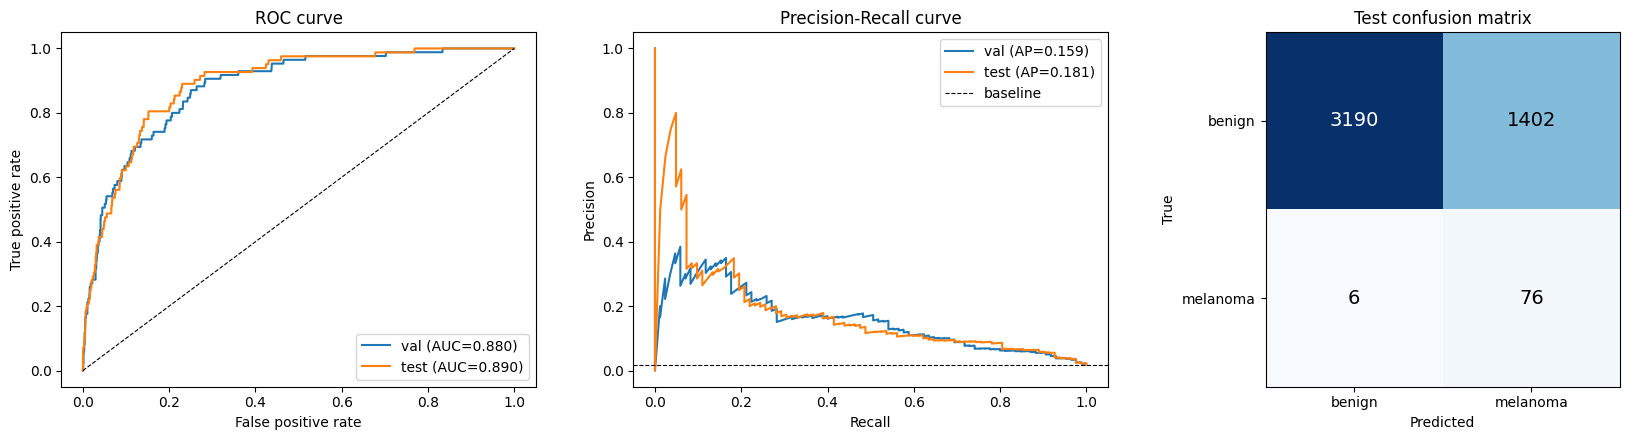

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# ROC
for y, p, lab in [(yv, pv, 'val'), (yt, pt, 'test')]:
    f, t, _ = roc_curve(y, p); ax[0].plot(f, t, label=f'{lab} (AUC={roc_auc_score(y, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curve'); ax[0].legend()

# Precision-Recall
for y, p, lab in [(yv, pv, 'val'), (yt, pt, 'test')]:
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=f'{lab} (AP={average_precision_score(y, p):.3f})')
ax[1].axhline(yt.mean(), color='k', ls='--', lw=0.8, label='baseline')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-Recall curve'); ax[1].legend()

# Confusion matrix on test
cm = confusion_matrix(yt, (pt >= thr_youden).astype(int))
ax[2].imshow(cm, cmap='Blues'); ax[2].set_title('Test confusion matrix')
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(['benign', 'melanoma']); ax[2].set_yticks([0, 1]); ax[2].set_yticklabels(['benign', 'melanoma'])
ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('True')
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
plt.tight_layout(); plt.show()

## 7. Notes

- **Which metric to trust:** with ~2% melanoma, plain accuracy is misleading (always predicting "benign" gets ~98%). Focus on **ROC-AUC, PR-AUC, sensitivity and specificity**.
- **Small test positives:** a patient-level test split may contain only a few hundred positives, so metrics are noisy. Treat differences of ~0.01 AUC as within noise.
- **Improving results:** try `IMG_SIZE`/cache of 256-384, unfreeze more blocks (`UNFREEZE_FROM = 4`), more epochs, EfficientNet-B1/B2, or average predictions with horizontal/vertical flip TTA.
- **Leakage comparison:** to reproduce the leakage demo, set `SPLIT_COL = 'split_random'` and compare test AUC with the patient split. It will look better but is over-optimistic.
- **More than 2 classes:** `metadata.csv` here only has the binary `target`. For multiclass (e.g. a diagnosis column), set the head to `nn.Linear(in_feats, K)`, use `nn.CrossEntropyLoss` with integer labels, and replace the sigmoid/ROC code with softmax + per-class / macro one-vs-rest AUC.